# Cleaning Pipeline - Exam Exercise Cropping

Ce notebook prépare les copies d'examen scannées pour la classification CNN.

**Objectif** : à partir de 10 dossiers de scans (1 par élève, 15 pages chacun), extraire les 30 exercices individuels de chaque copie.

**Étapes du pipeline** :
1. Suppression des annotations rouges (corrections du professeur)
2. Alignement des scans sur une référence (SET 1)
3. Découpe de chaque exercice selon des coordonnées prédéfinies
4. Export en deux structures : `by_exercise/` et `by_student/`

## 1. Imports et configuration

In [2]:
import cv2
import numpy as np
import json
from pathlib import Path
from IPython.display import display, Image as IPImage
import matplotlib.pyplot as plt

%matplotlib inline
plt.rcParams['figure.figsize'] = (12, 8)

In [3]:
DATA_DIR = Path("./data")        # dataset folder SET 1, SET 2, ..., SET 10
OUTPUT_DIR = Path("./data_clean")    # output folder
REF_SET_INDEX = 0                # index du SET de référence pour l'alignement (0 = SET 1)

## 2. Configuration des zones de découpe

Chaque page de l'examen contient un nombre fixe d'exercices. Les coordonnées sont **relatives** (entre 0 et 1) par rapport aux dimensions de l'image, ce qui rend le système indépendant de la résolution du scan.

Format : `[y_start, y_end, x_start, x_end]`

- Page 01 = page de garde, pas d'exercice
- Page 03 = 4 exercices (Q3 à Q6)
- Toutes les autres pages = 2 exercices chacune

In [4]:
CROP_CONFIG = {
    "02": {
        "q01": [0.03, 0.47, 0.04, 0.96],
        "q02": [0.47, 0.93, 0.04, 0.96]
    },
    "03": {
        "q03": [0.03, 0.28, 0.04, 0.96],
        "q04": [0.28, 0.50, 0.04, 0.96],
        "q05": [0.50, 0.73, 0.04, 0.96],
        "q06": [0.73, 0.93, 0.04, 0.96]
    },
    "04": {"q07": [0.03, 0.48, 0.04, 0.96], "q08": [0.48, 0.93, 0.04, 0.96]},
    "05": {"q09": [0.03, 0.48, 0.04, 0.96], "q10": [0.48, 0.93, 0.04, 0.96]},
    "06": {"q11": [0.03, 0.48, 0.04, 0.96], "q12": [0.48, 0.93, 0.04, 0.96]},
    "07": {"q13": [0.03, 0.48, 0.04, 0.96], "q14": [0.48, 0.93, 0.04, 0.96]},
    "08": {"q15": [0.03, 0.48, 0.04, 0.96], "q16": [0.48, 0.93, 0.04, 0.96]},
    "09": {"q17": [0.03, 0.48, 0.04, 0.96], "q18": [0.48, 0.93, 0.04, 0.96]},
    "10": {"q19": [0.03, 0.48, 0.04, 0.96], "q20": [0.48, 0.93, 0.04, 0.96]},
    "11": {"q21": [0.03, 0.48, 0.04, 0.96], "q22": [0.48, 0.93, 0.04, 0.96]},
    "12": {"q23": [0.03, 0.48, 0.04, 0.96], "q24": [0.48, 0.93, 0.04, 0.96]},
    "13": {"q25": [0.03, 0.48, 0.04, 0.96], "q26": [0.48, 0.93, 0.04, 0.96]},
    "14": {"q27": [0.03, 0.48, 0.04, 0.96], "q28": [0.48, 0.93, 0.04, 0.96]},
    "15": {"q29": [0.03, 0.48, 0.04, 0.96], "q30": [0.48, 0.93, 0.04, 0.96]}
}

print(f"Pages configurées : {len(CROP_CONFIG)}")
print(f"Total exercices : {sum(len(q) for q in CROP_CONFIG.values())}")

Pages configurées : 14
Total exercices : 30


## 3. Fonctions du pipeline

### 3.1 Suppression des annotations rouges

Le professeur corrige au **stylo rouge**. Les élèves écrivent au **crayon gris**. L'énoncé est imprimé en **noir**.

On utilise l'espace colorimétrique HSV pour isoler les pixels rouges. Le rouge "wrappe" autour de la valeur de teinte (hue), donc il faut deux plages :
- Hue 0-12 (rouge orangé)
- Hue 165-180 (rouge violacé)

Les pixels rouges détectés sont remplacés par du blanc.

In [5]:
def remove_red_annotations(img):
    """Supprime les marques rouges (corrections prof) en les remplaçant par du blanc."""
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    
    # Le rouge wrappe en HSV, donc deux plages
    mask1 = cv2.inRange(hsv, (0, 40, 40), (12, 255, 255))    # rouge-orangé
    mask2 = cv2.inRange(hsv, (165, 40, 40), (180, 255, 255))  # rouge-violacé
    red_mask = mask1 | mask2
    
    # Dilatation légère pour attraper les bords des traits rouges
    kernel = np.ones((3, 3), np.uint8)
    red_mask = cv2.dilate(red_mask, kernel, iterations=1)
    
    # Remplacement par du blanc
    result = img.copy()
    result[red_mask > 0] = [255, 255, 255]
    
    return result

### 3.2 Alignement des scans

Les scans ne sont jamais parfaitement alignés (légers décalages, rotations). Pour que les zones de crop soient cohérentes entre les élèves, on aligne chaque scan sur une image de référence (SET 1 par défaut).

**Méthode** : 
1. Détection de features ORB (Oriented FAST and Rotated BRIEF)
2. Matching avec BFMatcher + test de ratio de Lowe (filtre les mauvais matchs)
3. Calcul d'une homographie (transformation perspective) via RANSAC
4. Application de la transformation (warpPerspective)

Si pas assez de features ou si l'homographie échoue, on fait un simple resize à la taille de la référence.

In [6]:
def align_to_reference(img, ref_img, max_features=1000):
    """Aligne img sur ref_img via ORB + homographie RANSAC."""
    gray_img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    gray_ref = cv2.cvtColor(ref_img, cv2.COLOR_BGR2GRAY)
    
    # Détection ORB
    orb = cv2.ORB_create(max_features)
    kp1, des1 = orb.detectAndCompute(gray_img, None)
    kp2, des2 = orb.detectAndCompute(gray_ref, None)
    
    if des1 is None or des2 is None or len(kp1) < 10 or len(kp2) < 10:
        print("    [WARN] Pas assez de features, alignement ignoré")
        return cv2.resize(img, (ref_img.shape[1], ref_img.shape[0]))
    
    # Matching + ratio test de Lowe
    bf = cv2.BFMatcher(cv2.NORM_HAMMING, crossCheck=False)
    matches = bf.knnMatch(des1, des2, k=2)
    
    good_matches = []
    for m_pair in matches:
        if len(m_pair) == 2:
            m, n = m_pair
            if m.distance < 0.75 * n.distance:
                good_matches.append(m)
    
    if len(good_matches) < 10:
        print(f"    [WARN] Seulement {len(good_matches)} bons matchs, alignement ignoré")
        return cv2.resize(img, (ref_img.shape[1], ref_img.shape[0]))
    
    # Homographie RANSAC
    src_pts = np.float32([kp1[m.queryIdx].pt for m in good_matches]).reshape(-1, 1, 2)
    dst_pts = np.float32([kp2[m.trainIdx].pt for m in good_matches]).reshape(-1, 1, 2)
    
    H, mask = cv2.findHomography(src_pts, dst_pts, cv2.RANSAC, 5.0)
    
    if H is None:
        print("    [WARN] Homographie échouée, alignement ignoré")
        return cv2.resize(img, (ref_img.shape[1], ref_img.shape[0]))
    
    h, w = ref_img.shape[:2]
    aligned = cv2.warpPerspective(img, H, (w, h), borderMode=cv2.BORDER_REPLICATE)
    
    inliers = mask.ravel().sum() if mask is not None else 0
    print(f"    Aligné ({inliers}/{len(good_matches)} inliers)")
    
    return aligned

### 3.3 Découpe des exercices

Chaque exercice est découpé avec des coordonnées relatives `[y1, y2, x1, x2]` (entre 0 et 1). On multiplie par les dimensions réelles de l'image pour obtenir les pixels.

In [7]:
def crop_question(img, coords):
    """Découpe un exercice avec des coordonnées relatives [y1, y2, x1, x2]."""
    h, w = img.shape[:2]
    y1, y2, x1, x2 = coords
    py1, py2 = int(y1 * h), int(y2 * h)
    px1, px2 = int(x1 * w), int(x2 * w)
    
    # Clamping aux limites de l'image
    py1 = max(0, min(py1, h))
    py2 = max(0, min(py2, h))
    px1 = max(0, min(px1, w))
    px2 = max(0, min(px2, w))
    
    return img[py1:py2, px1:px2]

### 3.4 Utilitaires pour trouver les fichiers

In [8]:
def find_sets(data_dir):
    """Trouve tous les dossiers SET dans le dossier data."""
    data_path = Path(data_dir)
    sets = sorted([d for d in data_path.iterdir() 
                   if d.is_dir() and d.name.upper().startswith("SET")])
    if not sets:
        sets = sorted([d for d in data_path.iterdir() if d.is_dir()])
    return sets


def find_page_image(set_dir, page_num):
    """Trouve l'image d'une page dans un dossier SET."""
    page_str = f"{page_num:02d}"
    extensions = [".jpg", ".jpeg", ".png", ".JPG", ".JPEG", ".PNG"]
    
    for ext in extensions:
        for pattern in [f"{page_str}{ext}", f"page_{page_str}{ext}", f"{page_num}{ext}"]:
            p = set_dir / pattern
            if p.exists():
                return p
    return None

## 4. Découverte des données

Avant de lancer le pipeline, on vérifie que les dossiers et images sont bien là.

In [10]:
sets = find_sets(DATA_DIR)
print(f"SETs trouvés : {len(sets)}")
for s in sets:
    images = list(s.glob("*.*"))
    print(f"  {s.name} : {len(images)} fichiers")

SETs trouvés : 20
  SET 1 : 16 fichiers
  SET 10 : 15 fichiers
  SET 11 : 16 fichiers
  SET 12 : 15 fichiers
  SET 13 : 16 fichiers
  SET 14 : 16 fichiers
  SET 15 : 15 fichiers
  SET 16 : 15 fichiers
  SET 17 : 16 fichiers
  SET 18 : 15 fichiers
  SET 19 : 15 fichiers
  SET 2 : 16 fichiers
  SET 20 : 15 fichiers
  SET 3 : 15 fichiers
  SET 4 : 15 fichiers
  SET 5 : 15 fichiers
  SET 6 : 16 fichiers
  SET 7 : 16 fichiers
  SET 8 : 15 fichiers
  SET 9 : 15 fichiers


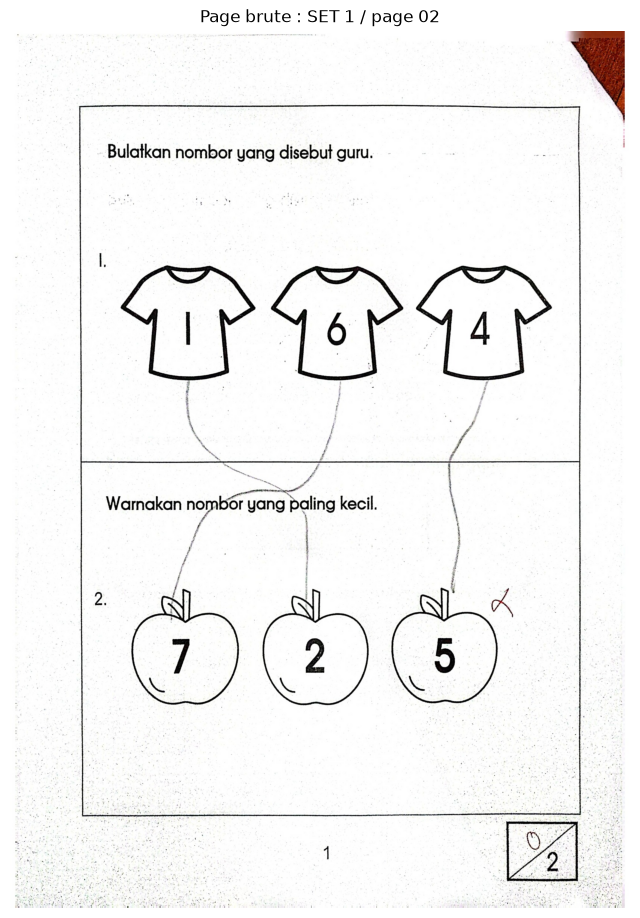

Dimensions : 1652x2338 px


In [11]:
# Aperçu d'une page brute (avant tout traitement)
sample_set = sets[0]
sample_path = find_page_image(sample_set, 2)  # page 2 = première page avec exercices
if sample_path:
    sample_img = cv2.imread(str(sample_path))
    plt.figure(figsize=(8, 12))
    plt.imshow(cv2.cvtColor(sample_img, cv2.COLOR_BGR2RGB))
    plt.title(f"Page brute : {sample_set.name} / page 02")
    plt.axis('off')
    plt.show()
    print(f"Dimensions : {sample_img.shape[1]}x{sample_img.shape[0]} px")
else:
    print("Page 02 non trouvée, vérifie le nommage des fichiers")

## 5. Démonstration du pipeline sur une page

On visualise chaque étape du traitement sur une page pour vérifier que tout fonctionne avant de lancer sur l'ensemble.

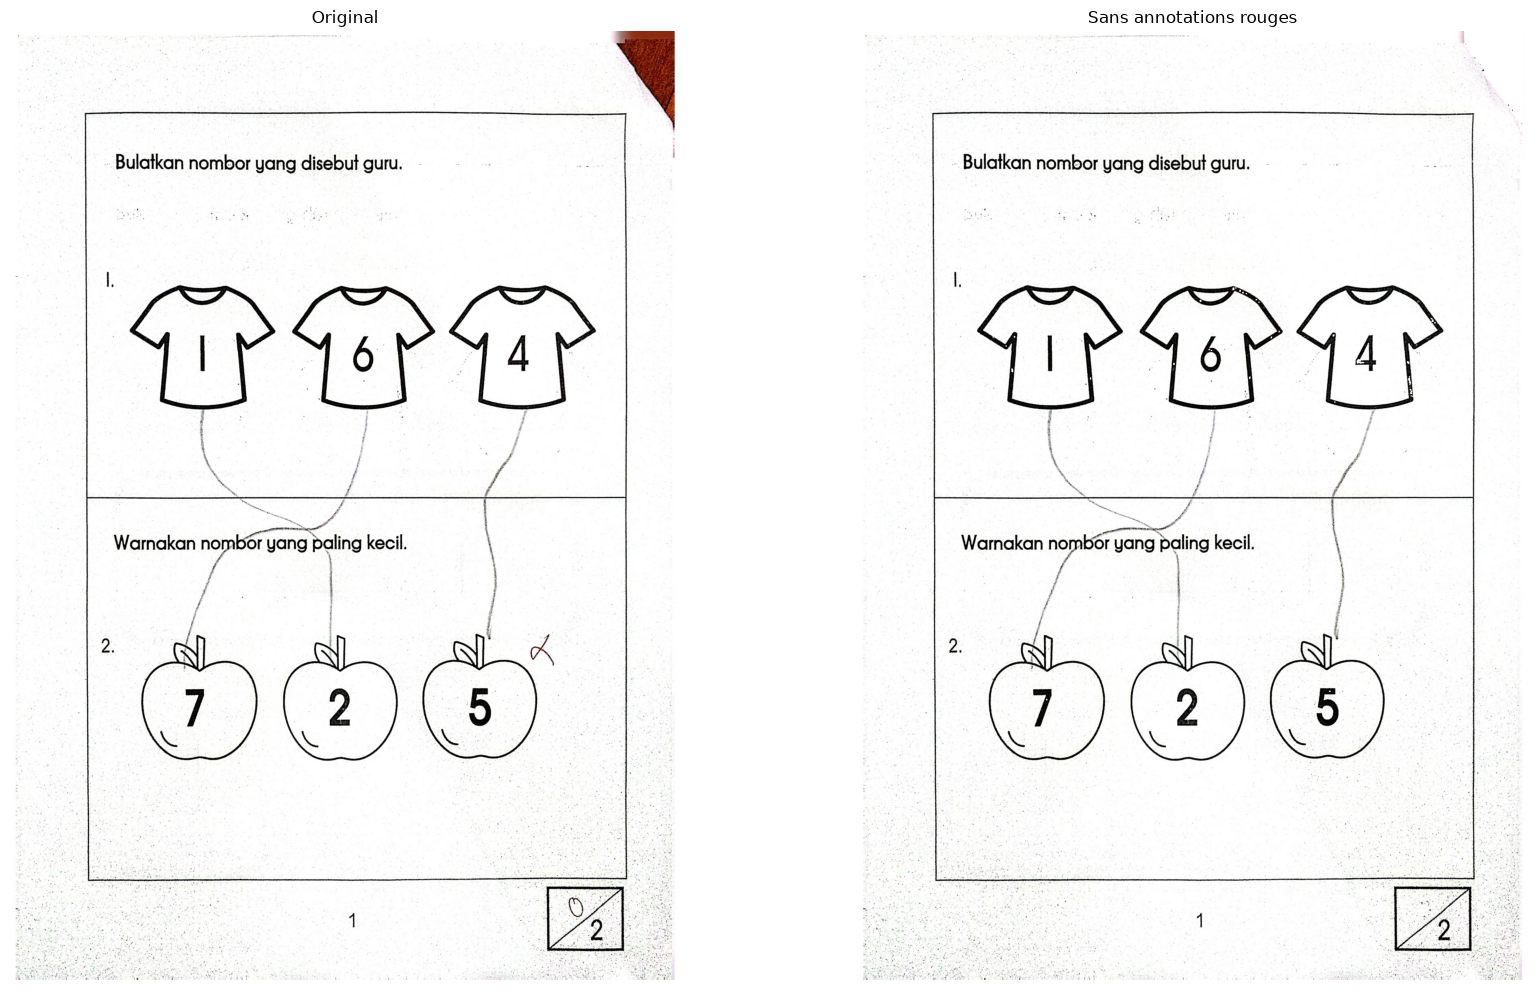

In [12]:
if sample_path:
    img = cv2.imread(str(sample_path))
    
    img_clean = remove_red_annotations(img)
    
    fig, axes = plt.subplots(1, 2, figsize=(18, 10))
    axes[0].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    axes[0].set_title("Original")
    axes[0].axis('off')
    
    axes[1].imshow(cv2.cvtColor(img_clean, cv2.COLOR_BGR2RGB))
    axes[1].set_title("Sans annotations rouges")
    axes[1].axis('off')
    
    plt.tight_layout()
    plt.show()

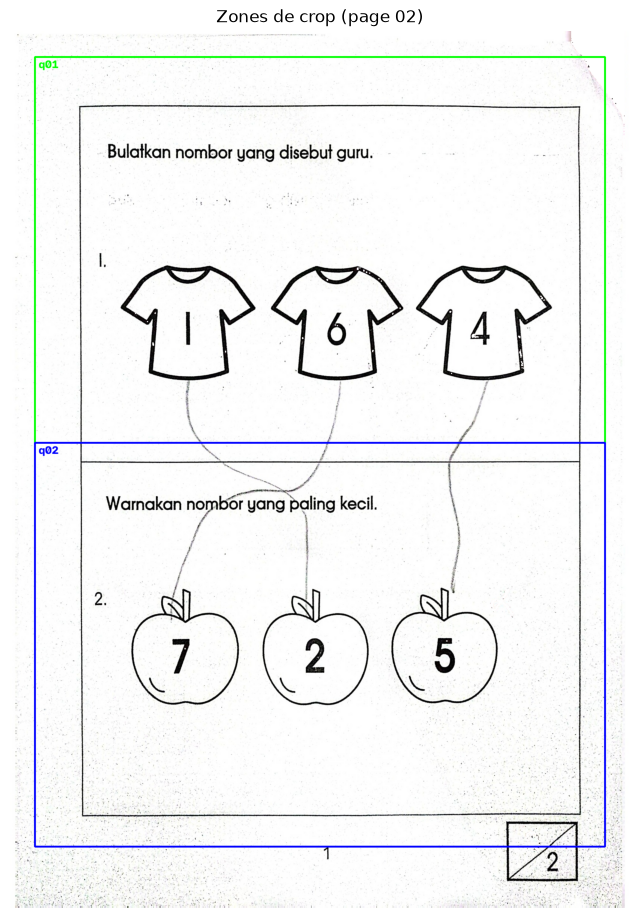

In [13]:
# Visualisation des zones de crop sur la page nettoyée
if sample_path:
    img_debug = img_clean.copy()
    h, w = img_debug.shape[:2]
    colors = [(0, 255, 0), (255, 0, 0), (0, 0, 255), (255, 255, 0)]
    
    page_config = CROP_CONFIG.get("02", {})
    for i, (q_name, coords) in enumerate(page_config.items()):
        y1, y2, x1, x2 = coords
        pt1 = (int(x1 * w), int(y1 * h))
        pt2 = (int(x2 * w), int(y2 * h))
        color = colors[i % len(colors)]
        cv2.rectangle(img_debug, pt1, pt2, color, 3)
        cv2.putText(img_debug, q_name, (pt1[0] + 10, pt1[1] + 30),
                    cv2.FONT_HERSHEY_SIMPLEX, 1, color, 2)
    
    plt.figure(figsize=(8, 12))
    plt.imshow(cv2.cvtColor(img_debug, cv2.COLOR_BGR2RGB))
    plt.title("Zones de crop (page 02)")
    plt.axis('off')
    plt.show()

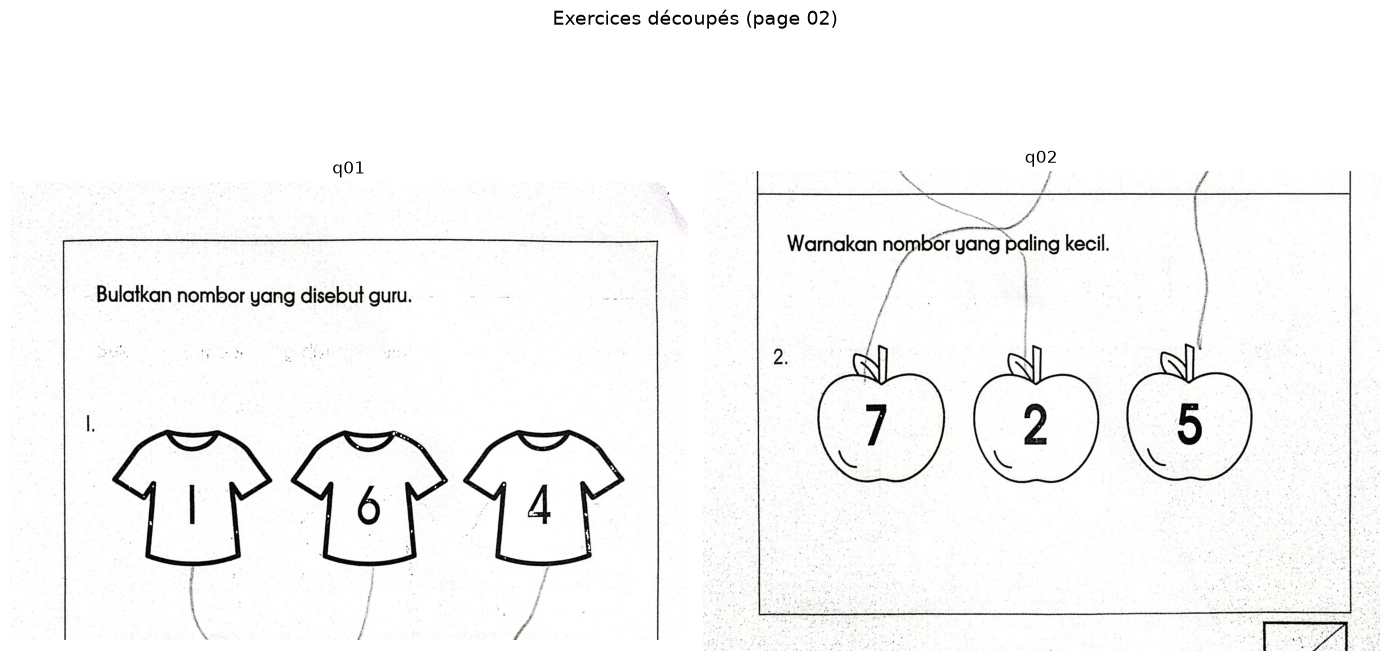

In [14]:
# Aperçu des crops individuels
if sample_path:
    page_config = CROP_CONFIG.get("02", {})
    fig, axes = plt.subplots(1, len(page_config), figsize=(14, 8))
    if len(page_config) == 1:
        axes = [axes]
    
    for ax, (q_name, coords) in zip(axes, page_config.items()):
        crop = crop_question(img_clean, coords)
        ax.imshow(cv2.cvtColor(crop, cv2.COLOR_BGR2RGB))
        ax.set_title(q_name)
        ax.axis('off')
    
    plt.suptitle("Exercices découpés (page 02)", fontsize=14)
    plt.tight_layout()
    plt.show()

## 6. Exécution du pipeline complet

On traite maintenant les 10 SETs. Pour chaque page de chaque SET :
1. Suppression du rouge
2. Suppression de la case de note
3. Alignement sur la référence (SET 1)
4. Découpe des exercices

**Sortie** :
- `by_exercise/q01/` ... `by_exercise/q30/` : tous les élèves pour un exercice donné (utile pour comparer)
- `by_student/set_1/` ... `by_student/set_10/` : tous les exercices d'un élève donné

In [15]:
# Création des dossiers de sortie
by_exercise_dir = OUTPUT_DIR / "by_exercise"
by_student_dir = OUTPUT_DIR / "by_student"
verify_dir = OUTPUT_DIR / "verify"

by_exercise_dir.mkdir(parents=True, exist_ok=True)
by_student_dir.mkdir(parents=True, exist_ok=True)
verify_dir.mkdir(parents=True, exist_ok=True)

print("Dossiers de sortie créés")

Dossiers de sortie créés


In [16]:
# Chargement des images de référence (SET 1)
ref_set = sets[REF_SET_INDEX]
print(f"Référence pour l'alignement : {ref_set.name}")

ref_images = {}
for page_str in CROP_CONFIG.keys():
    page_num = int(page_str)
    img_path = find_page_image(ref_set, page_num)
    if img_path:
        ref_images[page_str] = cv2.imread(str(img_path))
        if ref_images[page_str] is None:
            print(f"  [WARN] Impossible de lire {img_path}")
    else:
        print(f"  [WARN] Page {page_str} non trouvée dans {ref_set.name}")

print(f"Images de référence chargées : {len(ref_images)}/{len(CROP_CONFIG)}")

Référence pour l'alignement : SET 1
Images de référence chargées : 14/14


In [17]:
# Pipeline principal
stats = {"processed": 0, "skipped": 0, "empty_crops": 0}

for set_dir in sets:
    set_name = set_dir.name.lower().replace(" ", "_")
    print(f"\n{'='*50}")
    print(f"Traitement de {set_dir.name}...")
    
    # Dossier élève
    student_dir = by_student_dir / set_name
    student_dir.mkdir(parents=True, exist_ok=True)
    
    # Dossier vérification
    verify_set_dir = verify_dir / set_name
    verify_set_dir.mkdir(parents=True, exist_ok=True)
    
    for page_str, questions in CROP_CONFIG.items():
        page_num = int(page_str)
        img_path = find_page_image(set_dir, page_num)
        
        if img_path is None:
            print(f"  Page {page_str} : NON TROUVÉE")
            stats["skipped"] += 1
            continue
        
        img = cv2.imread(str(img_path))
        if img is None:
            print(f"  Page {page_str} : ILLISIBLE")
            stats["skipped"] += 1
            continue
        
        print(f"  Page {page_str} ({len(questions)} exercices)...")
        
        img_clean = remove_red_annotations(img)
        
        
        # Étape 3 : alignement
        if set_dir != ref_set and page_str in ref_images:
            img_aligned = align_to_reference(img_clean, ref_images[page_str])
        else:
            img_aligned = img_clean
        
        # Étape 4 : découpe
        for q_name, coords in questions.items():
            crop = crop_question(img_aligned, coords)
            
            if crop.size == 0:
                print(f"    {q_name} : crop vide !")
                stats["empty_crops"] += 1
                continue
            
            filename = f"{set_name}_{q_name}.jpg"
            
            # by_exercise
            exercise_dir = by_exercise_dir / q_name
            exercise_dir.mkdir(parents=True, exist_ok=True)
            cv2.imwrite(str(exercise_dir / filename), crop)
            
            # by_student
            cv2.imwrite(str(student_dir / f"{q_name}.jpg"), crop)
            
            stats["processed"] += 1
        
        # Sauvegarde vérification : zones de crop dessinées
        img_debug = img_aligned.copy()
        h, w = img_debug.shape[:2]
        colors = [(0, 255, 0), (255, 0, 0), (0, 0, 255), (255, 255, 0)]
        for i, (q_name, coords) in enumerate(questions.items()):
            y1, y2, x1, x2 = coords
            pt1 = (int(x1 * w), int(y1 * h))
            pt2 = (int(x2 * w), int(y2 * h))
            color = colors[i % len(colors)]
            cv2.rectangle(img_debug, pt1, pt2, color, 3)
            cv2.putText(img_debug, q_name, (pt1[0] + 10, pt1[1] + 30),
                        cv2.FONT_HERSHEY_SIMPLEX, 1, color, 2)
        cv2.imwrite(str(verify_set_dir / f"page_{page_str}_zones.jpg"), img_debug)

print(f"\n{'='*50}")
print(f"TERMINÉ !")
print(f"Crops générés : {stats['processed']}")
print(f"Pages ignorées : {stats['skipped']}")
print(f"Crops vides : {stats['empty_crops']}")


Traitement de SET 1...
  Page 02 (2 exercices)...
  Page 03 (4 exercices)...
  Page 04 (2 exercices)...
  Page 05 (2 exercices)...
  Page 06 (2 exercices)...
  Page 07 (2 exercices)...
  Page 08 (2 exercices)...
  Page 09 (2 exercices)...
  Page 10 (2 exercices)...
  Page 11 (2 exercices)...
  Page 12 (2 exercices)...
  Page 13 (2 exercices)...
  Page 14 (2 exercices)...
  Page 15 (2 exercices)...

Traitement de SET 10...
  Page 02 (2 exercices)...
    Aligné (29/74 inliers)
  Page 03 (4 exercices)...
    Aligné (52/99 inliers)
  Page 04 (2 exercices)...
    Aligné (29/97 inliers)
  Page 05 (2 exercices)...
    Aligné (26/120 inliers)
  Page 06 (2 exercices)...
    Aligné (45/111 inliers)
  Page 07 (2 exercices)...
    Aligné (39/99 inliers)
  Page 08 (2 exercices)...
    Aligné (29/68 inliers)
  Page 09 (2 exercices)...
    Aligné (46/93 inliers)
  Page 10 (2 exercices)...
    Aligné (55/112 inliers)
  Page 11 (2 exercices)...
    Aligné (55/77 inliers)
  Page 12 (2 exercices)...
   

## 7. Vérification des résultats

On affiche quelques crops pour vérifier visuellement que les zones sont correctes et que le rouge a bien été supprimé.

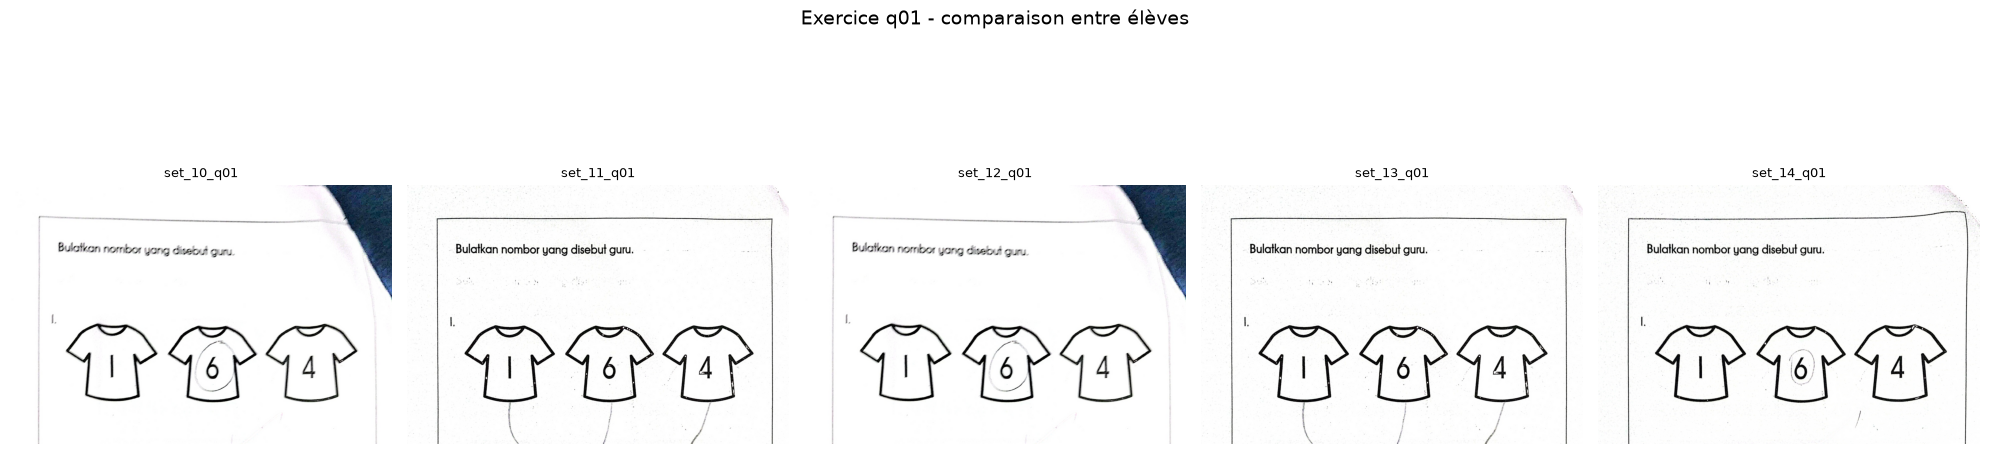

In [18]:
# Vérification : comparer le même exercice entre plusieurs élèves
exercise_to_check = "q01"  # modifier pour vérifier d'autres exercices

exercise_path = by_exercise_dir / exercise_to_check
if exercise_path.exists():
    crops = sorted(exercise_path.glob("*.jpg"))[:5]  # 5 premiers
    
    fig, axes = plt.subplots(1, len(crops), figsize=(20, 6))
    if len(crops) == 1:
        axes = [axes]
    
    for ax, crop_path in zip(axes, crops):
        crop_img = cv2.imread(str(crop_path))
        ax.imshow(cv2.cvtColor(crop_img, cv2.COLOR_BGR2RGB))
        ax.set_title(crop_path.stem, fontsize=9)
        ax.axis('off')
    
    plt.suptitle(f"Exercice {exercise_to_check} - comparaison entre élèves", fontsize=14)
    plt.tight_layout()
    plt.show()
else:
    print(f"Dossier {exercise_to_check} non trouvé")

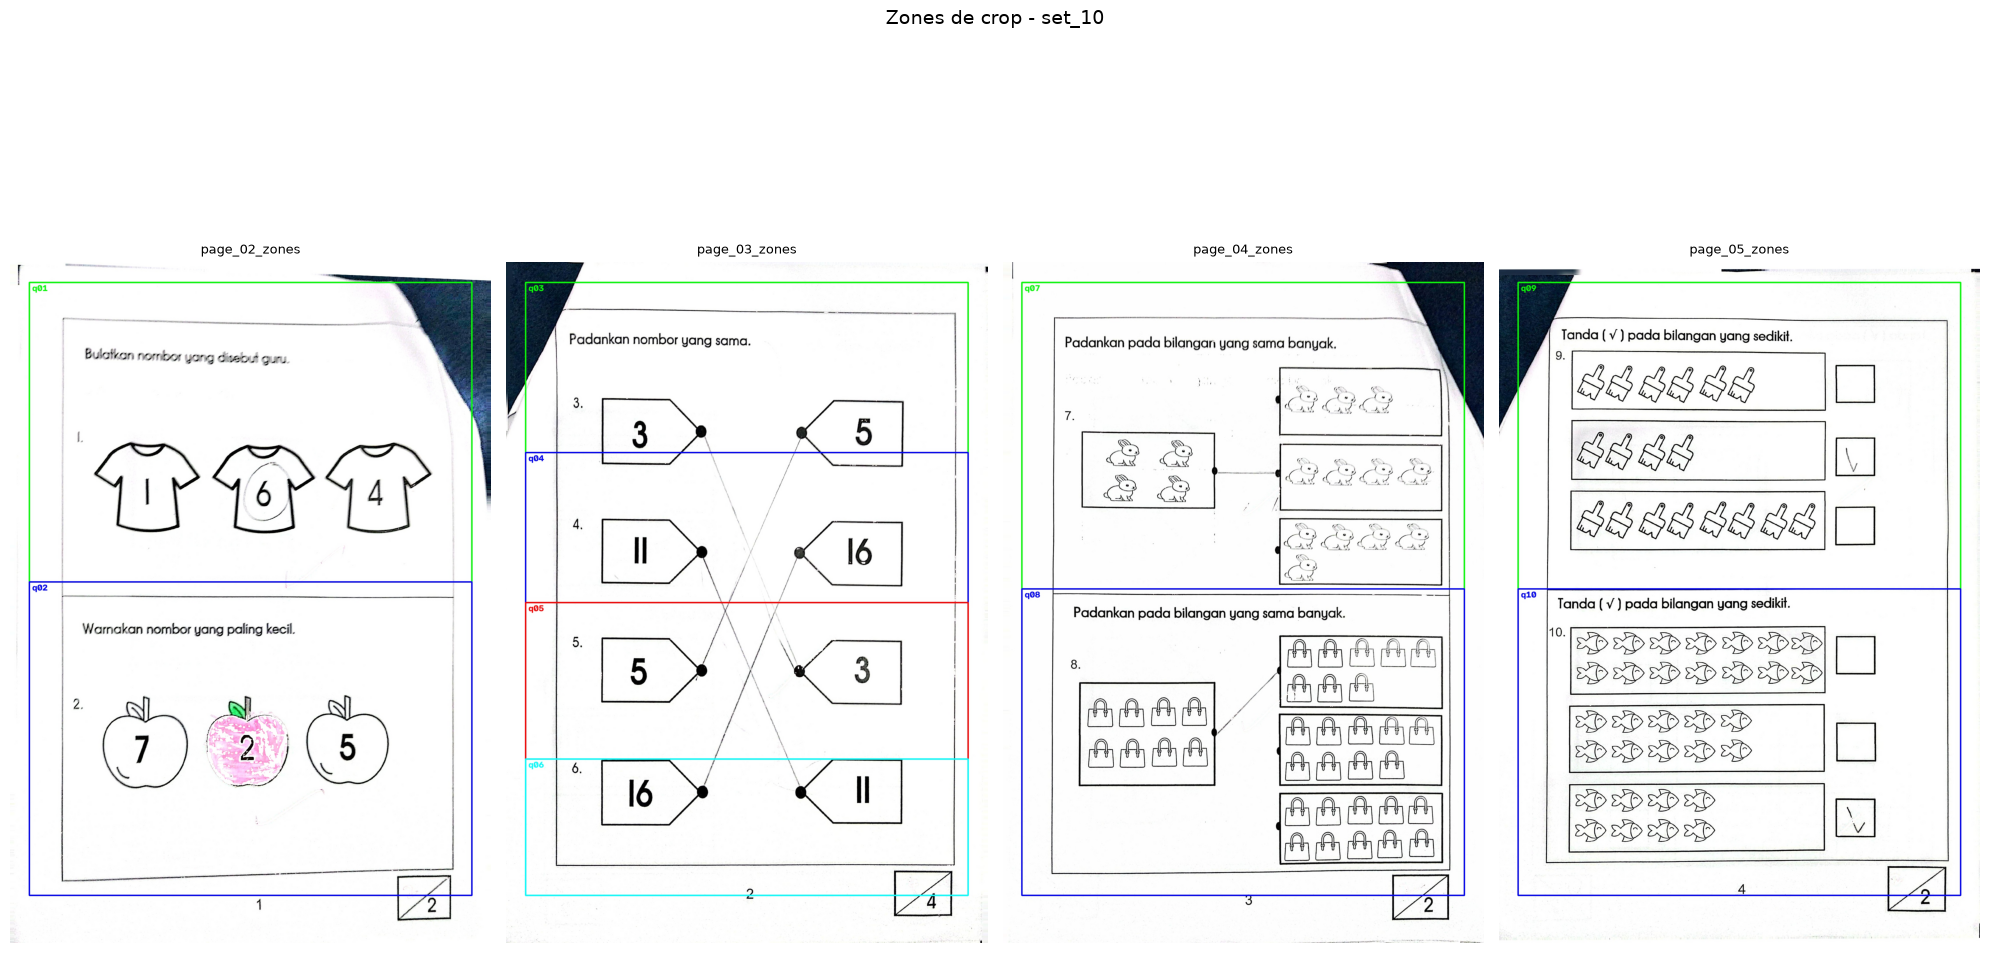

In [ ]:
# Vérification : afficher les zones de crop pour un SET donné
set_to_check = sets[1].name.lower().replace(" ", "_") if len(sets) > 1 else sets[0].name.lower().replace(" ", "_")

verify_set_path = verify_dir / set_to_check
if verify_set_path.exists():
    zone_files = sorted(verify_set_path.glob("*_zones.jpg"))[:4]
    
    fig, axes = plt.subplots(1, len(zone_files), figsize=(20, 12))
    if len(zone_files) == 1:
        axes = [axes]
    
    for ax, zf in zip(axes, zone_files):
        zone_img = cv2.imread(str(zf))
        ax.imshow(cv2.cvtColor(zone_img, cv2.COLOR_BGR2RGB))
        ax.set_title(zf.stem, fontsize=9)
        ax.axis('off')
    
    plt.suptitle(f"Zones de crop - {set_to_check}", fontsize=14)
    plt.tight_layout()
    plt.show()

## 8. Statistiques du dataset

Récapitulatif de ce qui a été généré.

In [19]:
print("Structure de sortie :")
print(f"  {OUTPUT_DIR}/")
print(f"  +-- by_exercise/")

for q_dir in sorted(by_exercise_dir.iterdir()):
    if q_dir.is_dir():
        count = len(list(q_dir.glob("*.jpg")))
        print(f"  |   +-- {q_dir.name}/  ({count} images)")

print(f"  +-- by_student/")
for s_dir in sorted(by_student_dir.iterdir()):
    if s_dir.is_dir():
        count = len(list(s_dir.glob("*.jpg")))
        print(f"      +-- {s_dir.name}/  ({count} exercices)")

total = sum(1 for _ in by_exercise_dir.rglob("*.jpg"))
print(f"\nTotal crops : {total}")
print(f"Attendu : {len(sets)} élèves x 30 exercices = {len(sets) * 30}")

Structure de sortie :
  data_clean/
  +-- by_exercise/
  |   +-- q01/  (20 images)
  |   +-- q02/  (20 images)
  |   +-- q03/  (20 images)
  |   +-- q04/  (20 images)
  |   +-- q05/  (20 images)
  |   +-- q06/  (20 images)
  |   +-- q07/  (20 images)
  |   +-- q08/  (20 images)
  |   +-- q09/  (20 images)
  |   +-- q10/  (20 images)
  |   +-- q11/  (20 images)
  |   +-- q12/  (20 images)
  |   +-- q13/  (20 images)
  |   +-- q14/  (20 images)
  |   +-- q15/  (20 images)
  |   +-- q16/  (20 images)
  |   +-- q17/  (20 images)
  |   +-- q18/  (20 images)
  |   +-- q19/  (20 images)
  |   +-- q20/  (20 images)
  |   +-- q21/  (20 images)
  |   +-- q22/  (20 images)
  |   +-- q23/  (20 images)
  |   +-- q24/  (20 images)
  |   +-- q25/  (20 images)
  |   +-- q26/  (20 images)
  |   +-- q27/  (20 images)
  |   +-- q28/  (20 images)
  |   +-- q29/  (20 images)
  |   +-- q30/  (20 images)
  +-- by_student/
      +-- set_1/  (30 exercices)
      +-- set_10/  (30 exercices)
      +-- set_11/  (